# Ringdown analysis with calibration uncertainty

This notebook shows how to marginalise a rational-filter ringdown analysis over detector calibration uncertainty. We

1. inject a $(2,2,0)$ ringdown into coloured Gaussian noise for one detector (H1),
2. compute the likelihood over remnant mass and spin, with and without a calibration error injected into the data,
3. sample mass, spin and the calibration correction together with `emcee`.

The calibration correction is a spline in amplitude and phase, $R(f) = \left[1+\delta A(f)\right] e^{i\,\delta\phi(f)}$, defined at a few control frequencies around the QNM. It is applied to the data, and $|R(f)|^2$ to the noise PSD, because the off-source noise used for the PSD carries the same calibration error as the signal.

Plotting helpers live in `plot.py` next to this notebook. Besides `qnm_filter`, the notebook needs `emcee` and `corner`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
import numpy as np
import matplotlib.pyplot as pl
import qnm
import emcee
import qnm_filter
import plot

/Users/u1189543/Documents/ANU/code/qnm_filter/qnm_filter/utility.py:28: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


### Injection parameters

A GW150914-like remnant, observed by one detector.

In [3]:
mass = 68.5        # remnant mass, in solar masses
chi = 0.69         # remnant spin
model_list = [(2, 2, 0, 'p')]

srate = 4096       # sampling rate, in Hz
t_init = 0.0       # start of the ringdown (and of the analysis segment), in seconds
segment_length = 0.2
flow = 20          # high-pass frequency, in Hz
ringdown_snr = 60  # optimal SNR of the injected ringdown

rng = np.random.default_rng(1234)

Frequency and damping time of the $(2,2,0)$ mode

In [4]:
mass_unit = qnm_filter.Filter.mass_unit(mass)                  # mass in seconds
omega220 = qnm.modes_cache(s=-2, l=2, m=2, n=0)(a=chi)[0]      # in units of 1/mass
f220 = omega220.real / mass_unit / (2 * np.pi)
tau220 = -mass_unit / omega220.imag
print(f"f_220 = {f220:.1f} Hz, tau_220 = {tau220*1e3:.2f} ms")

f_220 = 249.2 Hz, tau_220 = 4.16 ms


### Construct detector noise

Gaussian noise coloured by the ASD in `asd.txt` (the same noise curve as `NRInjection_customized_noise.ipynb`). We draw one long stretch and split it into an on-source segment around the event and an off-source segment, earlier in time, used to estimate the PSD.

In [5]:
noise_curve = qnm_filter.Noise()
noise_curve.load_noise_curve("asd", "../asd.txt")

def coloured_noise(duration, srate, asd, rng, fmin=15):
    '''Gaussian noise with one-sided ASD `asd` (a RealData indexed by frequency).
    No noise below fmin: asd.txt holds a placeholder value of 1 below ~10 Hz,
    and the data are high-passed at 20 Hz anyway.'''
    n = int(duration * srate)
    freqs = np.fft.rfftfreq(n, d=1 / srate)
    psd = np.where(freqs >= fmin, np.interp(freqs, asd.time, asd.values**2), 0.0)
    white = rng.normal(size=len(freqs)) + 1j * rng.normal(size=len(freqs))
    return np.fft.irfft(white * np.sqrt(psd * srate * n / 4), n=n)

t_all = -60 + np.arange(64 * srate) / srate
noise_all = coloured_noise(64, srate, noise_curve.asd, rng)

on_source = (t_all >= -2) & (t_all < 2)       # 4 s around the event
off_source = (t_all >= -30) & (t_all < -14)   # 16 s for the PSD
t_on, t_off = t_all[on_source], t_all[off_source]
noise_on, noise_off = noise_all[on_source], noise_all[off_source]

### Construct the ringdown signal

A damped sinusoid that starts at `t_init`, scaled to the chosen optimal SNR

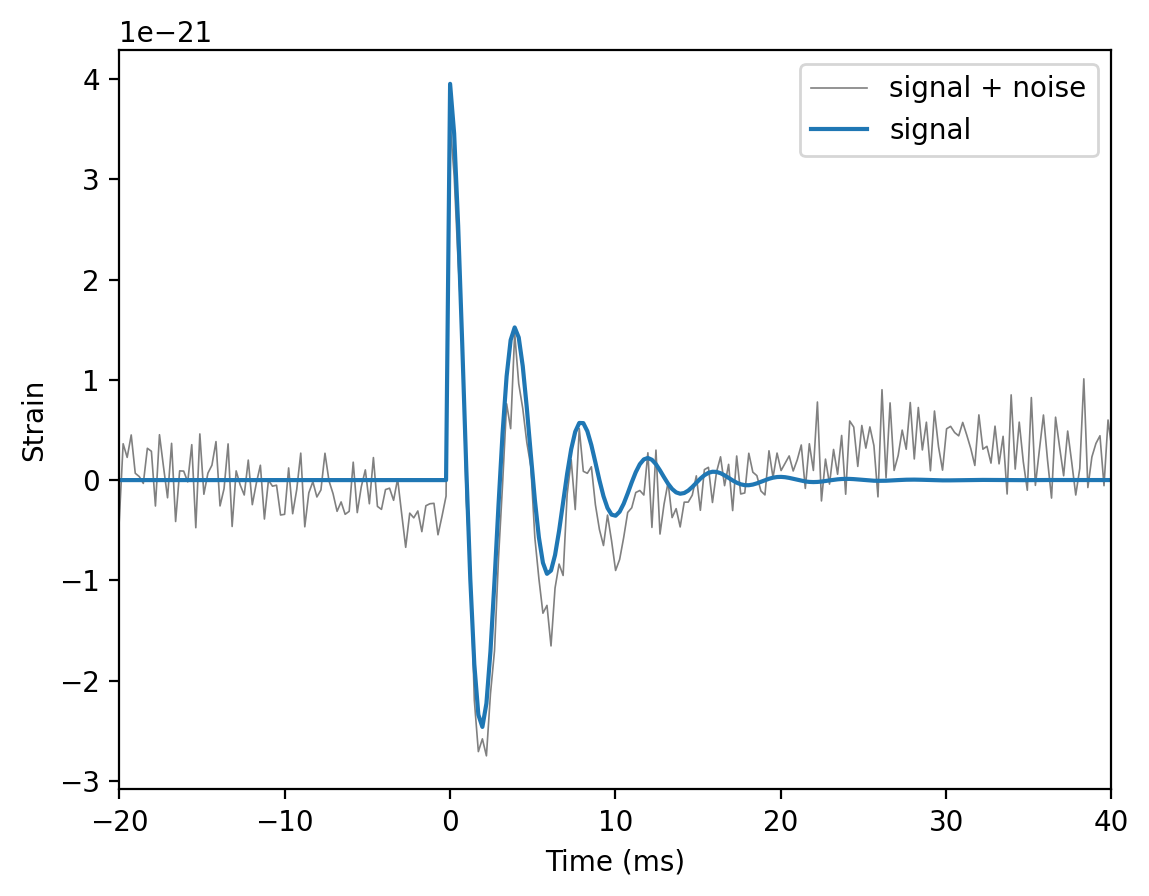

In [6]:
def optimal_snr(h, srate, asd, flow):
    freqs = np.fft.rfftfreq(len(h), d=1 / srate)
    h_f = np.fft.rfft(h) / srate
    psd = np.interp(freqs, asd.time, asd.values**2)
    band = freqs >= flow
    return np.sqrt(4 * np.sum(np.abs(h_f[band])**2 / psd[band]) * (freqs[1] - freqs[0]))

dt = t_on - t_init
signal = np.where(dt >= 0, np.real(np.exp(-1j * omega220 * dt / mass_unit)), 0.0)
signal *= ringdown_snr / optimal_snr(signal, srate, noise_curve.asd, flow)

pl.plot(t_on * 1e3, noise_on + signal, color='grey', lw=0.6, label='signal + noise')
pl.plot(t_on * 1e3, signal, label='signal')
pl.xlim(-20, 40)
pl.xlabel('Time (ms)')
pl.ylabel('Strain')
pl.legend()

### Ringdown analysis with rational filters

A helper that loads one data set into a `Network`. The covariance matrix is estimated with the Welch method from the off-source noise; `psd_floor` keeps it well conditioned below `flow`, and `eps_frac` adds a small diagonal jitter.

In [7]:
def build_network(strain, noise):
    fit = qnm_filter.Network(segment_length=segment_length, srate=srate, t_init=t_init)
    fit.original_data['H1'] = qnm_filter.RealData(strain, index=t_on, ifo='H1')
    fit.pure_noise = {'H1': qnm_filter.RealData(noise, index=t_off, ifo='H1')}
    fit.pure_signal = {'H1': qnm_filter.RealData(signal, index=t_on, ifo='H1')}
    fit.detector_alignment()

    fit.condition_data('original_data', flow=flow)
    fit.condition_data('pure_noise', flow=flow)
    fit.condition_data('pure_signal', flow=flow)

    fit.psd_floor = (flow, 1.0)
    fit.compute_acfs('pure_noise', sampling_rate=0.5)
    fit.cholesky_decomposition(eps_frac=1e-6)
    fit.first_index()
    return fit

#### Without calibration error

In [8]:
fit = build_network(noise_on + signal, noise_off)

Ringdown SNR

In [9]:
signal_seg = fit.truncate_data(fit.pure_signal)['H1']
fit.compute_SNR(fit.truncate_data(fit.original_data)['H1'], signal_seg, 'H1', False)

60.259737877401584

Likelihood over remnant mass and spin

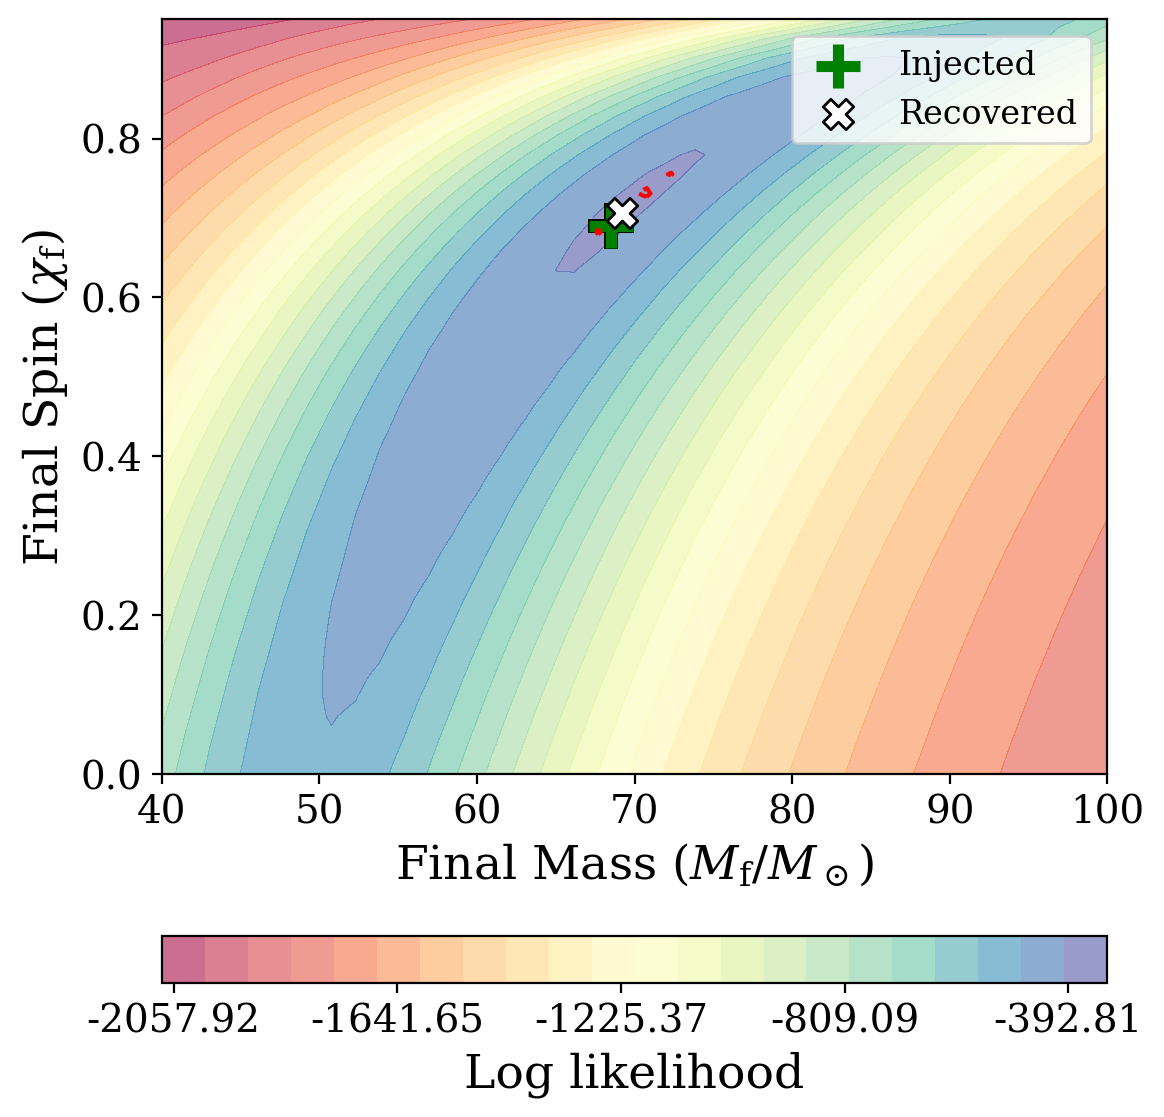

In [10]:
M_min, M_max, chi_min, chi_max = 40, 100, 0.0, 0.95
fig, massspace, chispace, likelihood_nominal = plot.plot_likelihood_vs_mass_spin(
    fit, mass, chi, M_min, M_max, chi_min, chi_max, n_points=40,
    num_cpu=-1, model_list=model_list)
fig

### Calibration error

A Gaussian bump centred on $f_{220}$: +20% in amplitude and +20° in phase at the peak, with a width of 50 Hz ($\pm 2\sigma$). Miscalibration divides the true strain by $R_\mathrm{true}(f)$; since the calibration model multiplies the data by $R(f)$, a correct recovery gives $R \approx R_\mathrm{true}$.

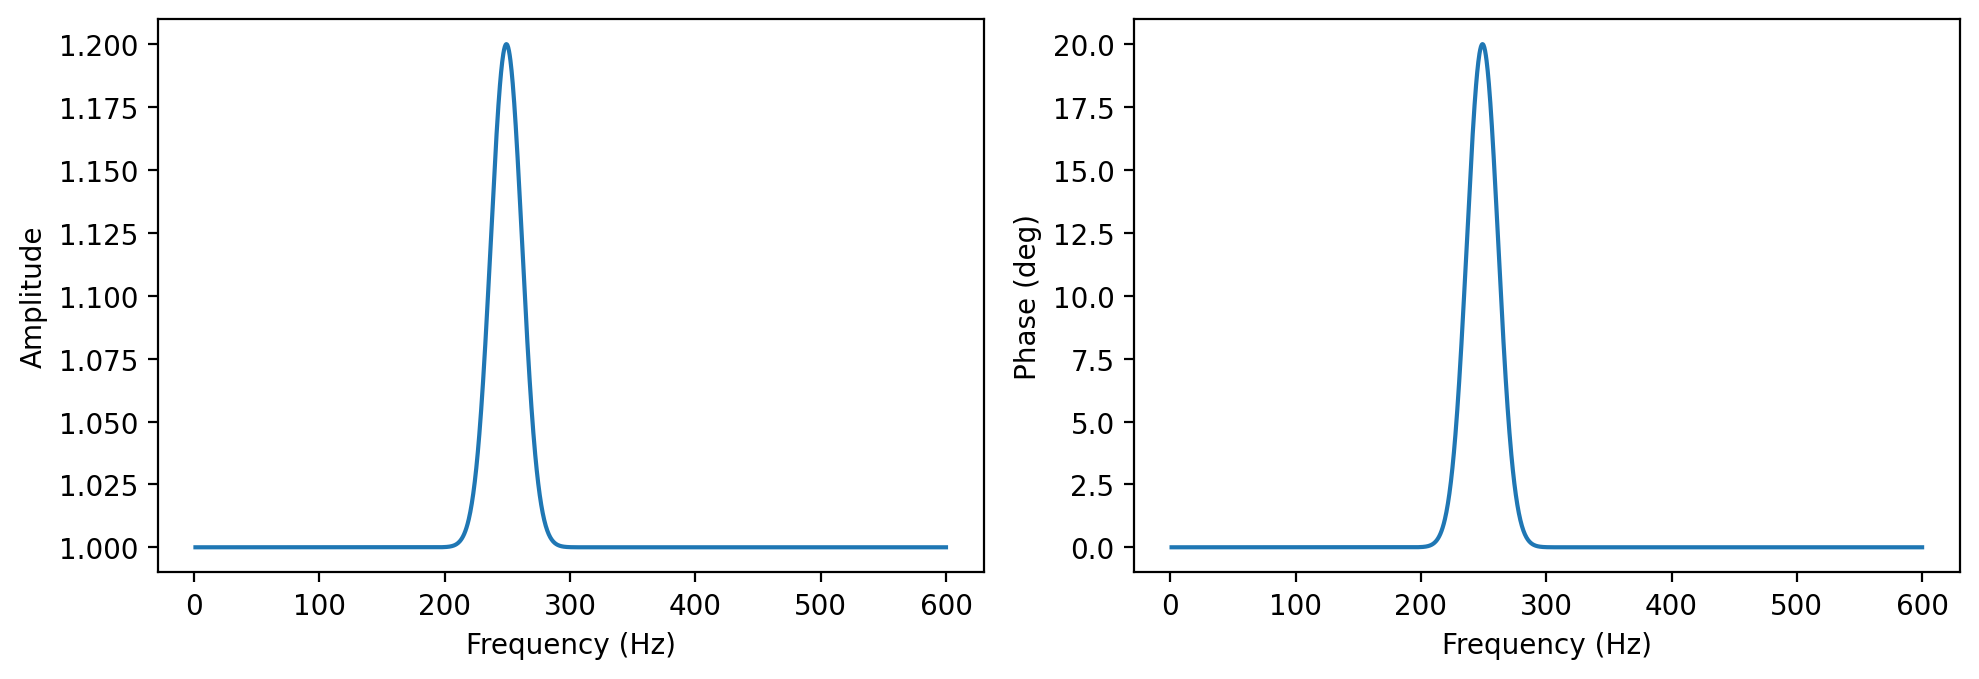

In [11]:
def true_response(freqs, amp=0.20, phase_deg=20.0, centre=f220, width=50.0):
    bump = np.exp(-0.5 * ((freqs - centre) / (width / 4))**2)
    return (1 + amp * bump) * np.exp(1j * np.deg2rad(phase_deg) * bump)

def miscalibrate(x, srate):
    '''Divide x by R_true in the frequency domain.'''
    freqs = np.fft.rfftfreq(len(x), d=1 / srate)
    return np.fft.irfft(np.fft.rfft(x) / true_response(freqs), n=len(x))

f_plot = np.linspace(1, 600, 2000)
fig, (ax1, ax2) = pl.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(f_plot, np.abs(true_response(f_plot)))
ax1.set_xlabel('Frequency (Hz)')
ax1.set_ylabel('Amplitude')
ax2.plot(f_plot, np.angle(true_response(f_plot), deg=True))
ax2.set_xlabel('Frequency (Hz)')
ax2.set_ylabel('Phase (deg)')
fig.tight_layout()

#### With the calibration error injected

The same noise and signal, with the calibration error applied to both the on-source data and the off-source noise

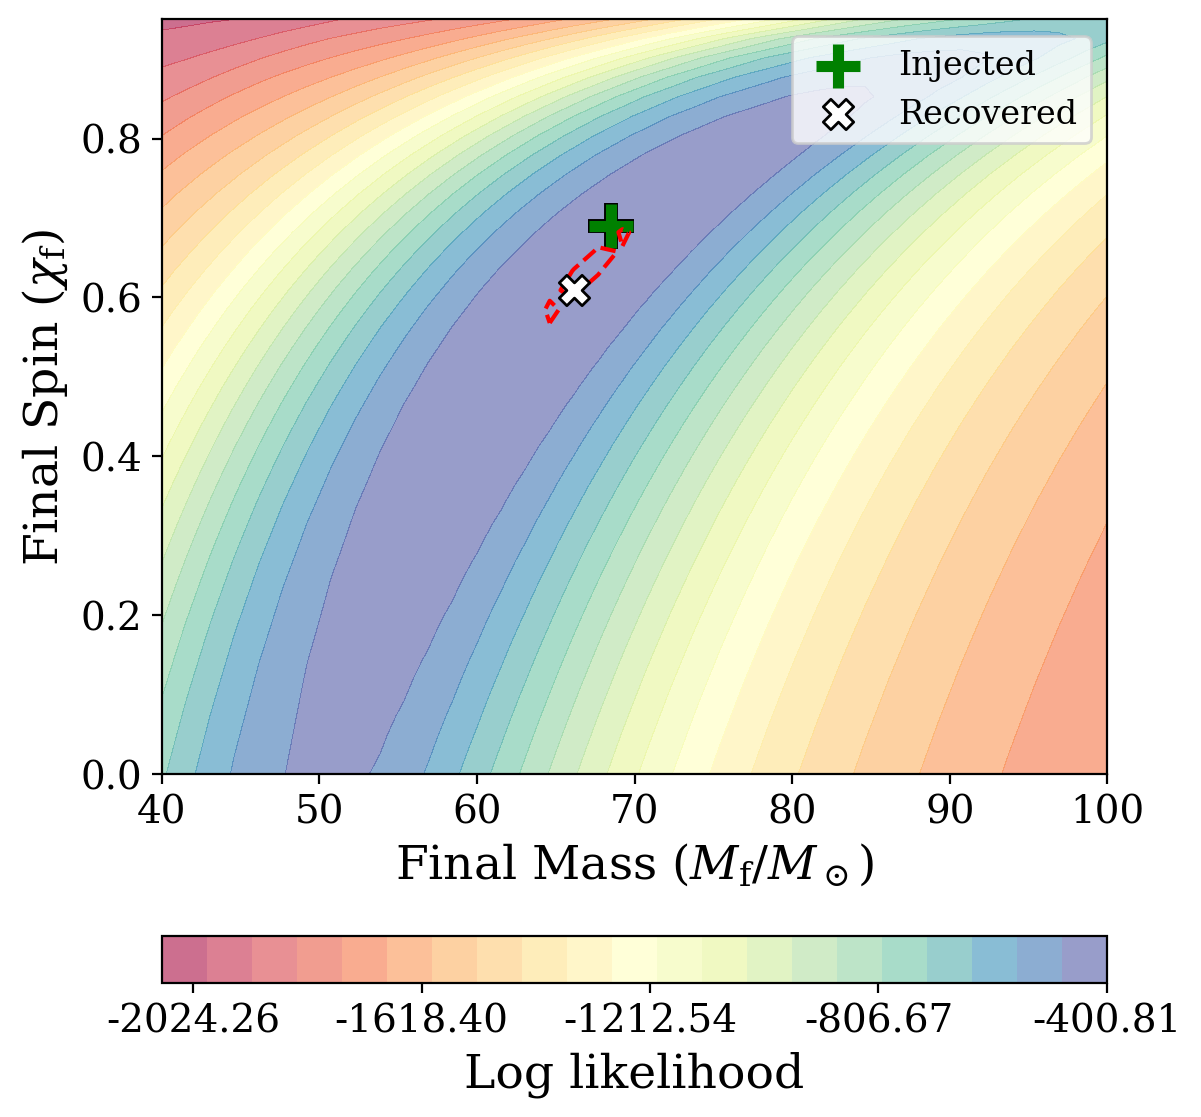

In [12]:
fit_err = build_network(miscalibrate(noise_on + signal, srate), miscalibrate(noise_off, srate))

fig, _, _, likelihood_err = plot.plot_likelihood_vs_mass_spin(
    fit_err, mass, chi, M_min, M_max, chi_min, chi_max, n_points=40,
    num_cpu=-1, model_list=model_list)
fig

### Calibration prior

Flat in frequency: median response 1, with 1-$\sigma$ uncertainties of 20% in amplitude and 20° in phase.

In [13]:
cal_freq = np.linspace(1, srate / 2, 2048)
ones = np.ones_like(cal_freq)
cal_prior = qnm_filter.Calibration_ErrUnc(
    cal_freq, mag=ones, radian=0 * ones,
    mag16=0.8 * ones, mag84=1.2 * ones,
    radian16=-np.deg2rad(20) * ones, radian84=np.deg2rad(20) * ones,
    ifo='H1',
)

### Sample mass, spin and calibration

Seven calibration control points, evenly spaced over $f_{220} \pm 50$ Hz. The end points are fixed to zero (`pin_boundaries=True`, the default), so five amplitude and five phase offsets are sampled together with mass and spin.

In [14]:
fctrl = {'H1': np.linspace(f220 - 50, f220 + 50, 7)}
priors = dict(M_min=M_min, M_max=M_max, chi_min=chi_min, chi_max=chi_max)

model = qnm_filter.CalibrationModel({'H1': cal_prior}, fctrl, priors)
log_prob = qnm_filter.CalibrationLogProb(model, fit_err, model_list)
print(model.ndim, 'parameters:', model.param_names)

12 parameters: ['M', 'chi', 'H1_delta_amp_0', 'H1_delta_amp_1', 'H1_delta_amp_2', 'H1_delta_amp_3', 'H1_delta_amp_4', 'H1_delta_phase_0', 'H1_delta_phase_1', 'H1_delta_phase_2', 'H1_delta_phase_3', 'H1_delta_phase_4']


Running the sampler takes a while (each step re-estimates the noise covariance with the trial calibration), so by default we load a chain saved from an earlier run of this cell. Set `RUN_MCMC = True` to rerun it; pass a `multiprocessing.Pool` to `emcee` to use several cores.

In [15]:
RUN_MCMC = False
chain_file = 'calibration_chain_H1.npz'
nwalkers, nsteps, nburn, thin = 32, 6000, 1000, 20

if RUN_MCMC:
    p0 = model.init_walkers(nwalkers=nwalkers, seed=42)
    sampler = emcee.EnsembleSampler(nwalkers, model.ndim, log_prob)
    sampler.run_mcmc(p0, nsteps, progress=True)
    samples = sampler.get_chain(discard=nburn, thin=thin, flat=True)
    np.savez_compressed(chain_file, samples=samples, param_names=model.param_names,
                        mass=mass, chi=chi, ringdown_snr=ringdown_snr)
else:
    samples = np.load(chain_file)['samples']

print(samples.shape)

(8000, 12)


### Recovered mass and spin

MAP: M = 69.5, chi = 0.69


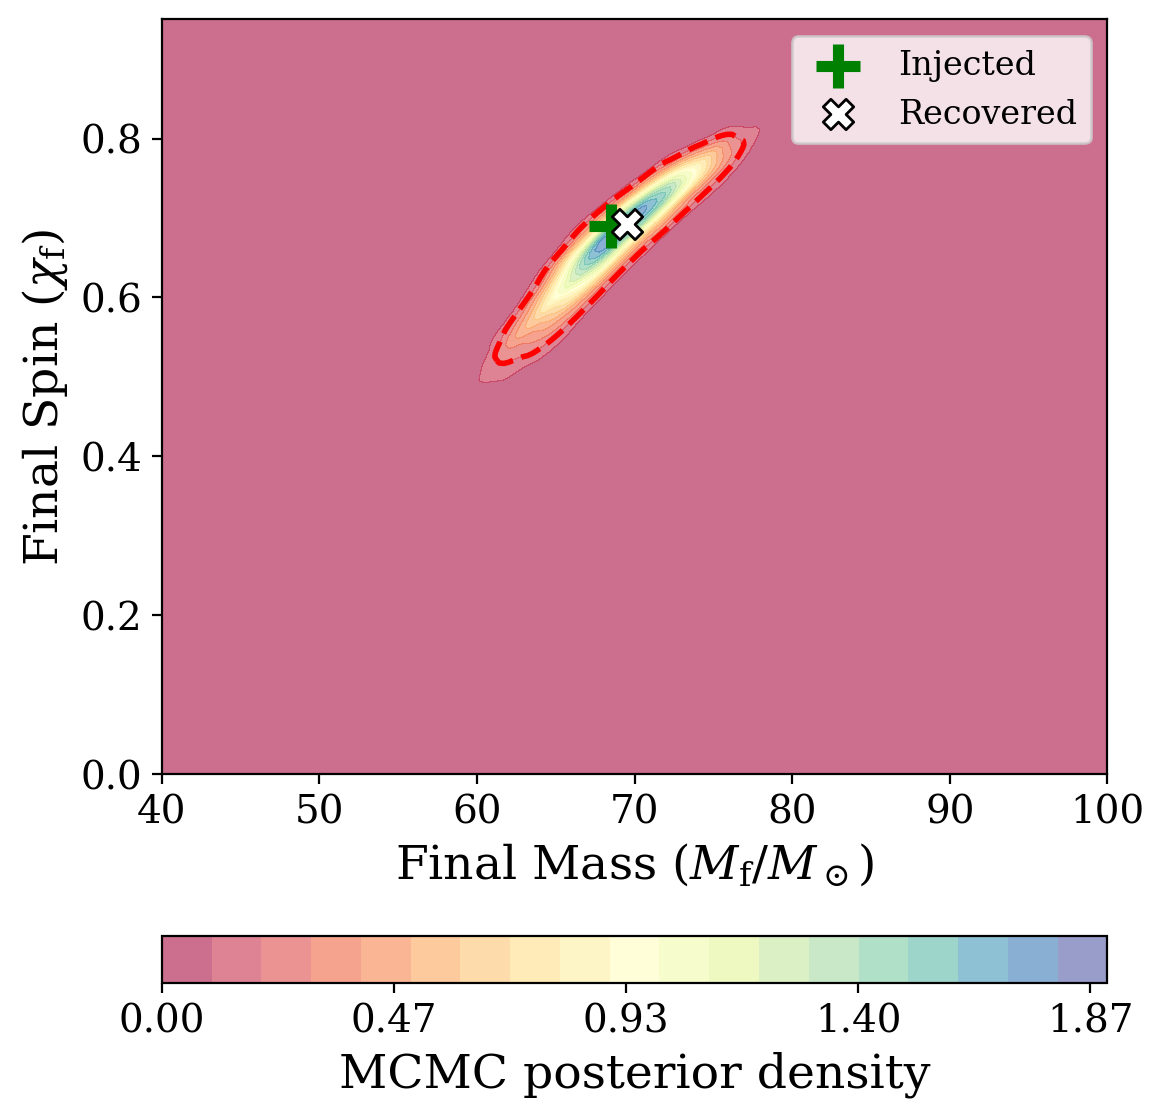

In [16]:
fig, M_map, chi_map = plot.plot_sampling_density_vs_mass_spin(
    samples, mass, chi, M_min, M_max, chi_min, chi_max, CI_level=90)
print(f"MAP: M = {M_map:.1f}, chi = {chi_map:.2f}")
fig

### Recovered calibration

Posterior on $R(f)$ (median, 68% and 90% bands) against the prior and the injected $R_\mathrm{true}(f)$

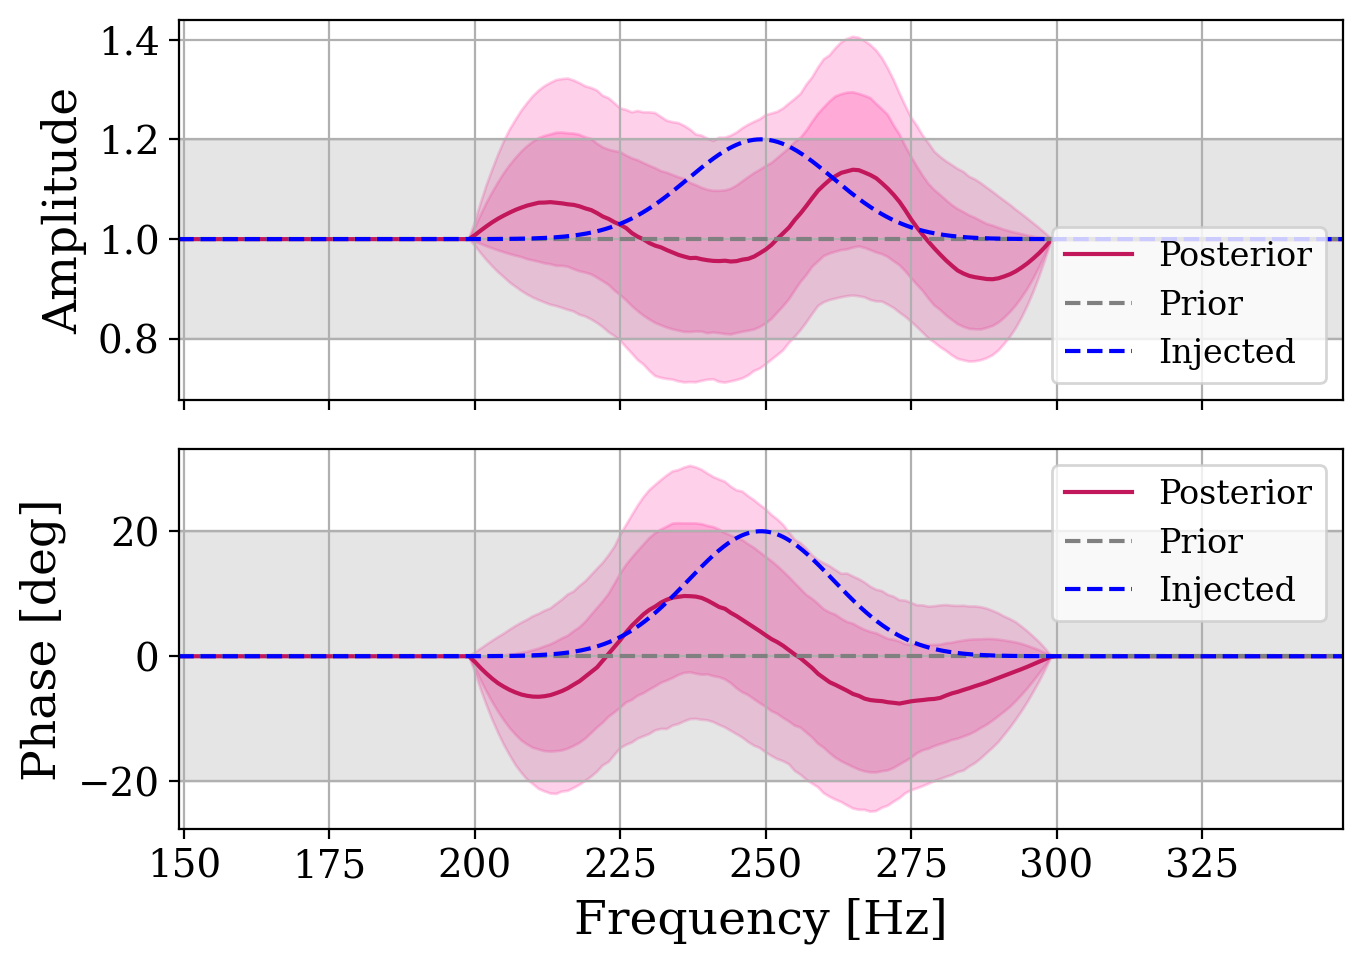

In [17]:
R_inj = true_response(f_plot)
fig = plot.plot_cal_response(
    samples, fctrl, cal_prior, None,
    truth=np.vstack([f_plot, np.abs(R_inj), np.angle(R_inj)]), truth_label='Injected',
    p_fmin=f220 - 100, p_fmax=f220 + 100)
fig